<a href="https://colab.research.google.com/github/manvi-smaran/1024160111_UCS420_CC_Assignments/blob/main/1024160111_A10_UCS420.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420: Cognitive Computing — Assignment 10
## Diabetes Care Information Assistant (Odd Roll Number)

A Python-based **Healthcare Cognitive Assistant** that understands a user query, identifies its **intent**, applies **reasoning rules**, retrieves information from a **domain knowledge base** and generates an appropriate response.

The notebook follows the *Logical Steps to build a Cognitive Assistant* from Lab 10:

| Step | Lab 10 step | Assignment requirement |
|---|---|---|
| 1 | Labelled Corpus | R1 – ≥ 40 queries, ≥ 5 intents |
| 2 | Taxonomy | R2 – ≥ 4 major categories × ≥ 2 subcategories |
| 3 | Ontology – Relationships | R3 – ≥ 8 concepts, ≥ 10 relationships |
| 4 | NLP Processing | R4 – lowercase, tokenize, stopwords, lemmatize |
| 5 | Learning | R5 – TF-IDF + Naive Bayes / Logistic Regression / SVM |
| 5b | Evaluation | R6 – accuracy, precision, recall, F1, confusion matrix |
| 6 | Reasoning & Knowledge Retrieval | R7 – knowledge base, R8 – ≥ 5 rules |
| 7 | Cognitive Assistant | R9 – integrate everything |
| 8 | Deployment | R10 – interactive interface in Google Colab |

> ⚠️ **Disclaimer:** This assistant gives general educational information only. It is not a substitute for professional medical advice.

## 0. Setup — install / import libraries and download NLTK data

In [ ]:


import re
import string
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

print("All libraries imported and NLTK data downloaded successfully!")

All libraries imported and NLTK data downloaded successfully!


## 1. Labelled Corpus — all queries with corresponding labels  *(Requirement 1)*

Same structure as the Lab 10 example (`corpus = {"Exam": [...], "Fees": [...]}`), i.e. a **dictionary of lists**: each key is an **intent label** and the value is the list of user queries for it.

**8 intent categories × 15 queries = 120 labelled queries.**

In [ ]:
corpus = {
    "About_Diabetes": [
        "What is diabetes?",
        "What are the different types of diabetes?",
        "What is the difference between type 1 and type 2 diabetes?",
        "What is gestational diabetes?",
        "What causes type 1 diabetes?",
        "Why does type 2 diabetes happen?",
        "What is prediabetes?",
        "Is diabetes a lifelong disease?",
        "Can children get diabetes?",
        "How is diabetes diagnosed?",
        "Explain diabetes mellitus in simple words.",
        "What happens in the body when you have diabetes?",
        "Is type 1 diabetes genetic?",
        "Which blood test confirms diabetes?",
        "What role does the pancreas play in diabetes?",
    ],
    "Symptoms": [
        "What are the symptoms of diabetes?",
        "What are the early signs of high blood sugar?",
        "Why am I always thirsty and urinating frequently?",
        "Can diabetes cause blurred vision?",
        "I feel tired all the time, could it be diabetes?",
        "What are the warning signs of type 2 diabetes?",
        "Why do my wounds heal so slowly?",
        "Is sudden weight loss a sign of diabetes?",
        "How does high sugar make you feel?",
        "I am always hungry and pee a lot at night, is that diabetes?",
        "What are the first signs that my sugar is high?",
        "Does diabetes make you feel dizzy and weak?",
        "Can frequent infections be a symptom of diabetes?",
        "My mouth is always dry and I feel thirsty, what does it mean?",
        "How do I know if I have diabetes?",
    ],
    "Diet": [
        "What should a diabetic eat?",
        "Which foods should diabetics avoid?",
        "Can a diabetic person eat rice?",
        "Is fruit safe for diabetics?",
        "What is a good breakfast for diabetes?",
        "How many carbohydrates should I eat per day?",
        "Are sugar free foods good for diabetes?",
        "What is the glycemic index of food?",
        "Can I eat sweets if I have diabetes?",
        "Suggest a healthy meal plan for diabetes.",
        "What snacks are healthy for diabetics?",
        "Is it okay to drink fruit juice with diabetes?",
        "How much sugar can a diabetic eat in a day?",
        "Which vegetables are best for controlling sugar?",
        "Can diabetics drink milk or tea?",
    ],
    "Exercise": [
        "What exercise is good for diabetes?",
        "How much should a diabetic walk daily?",
        "Does exercise lower blood sugar?",
        "Is yoga helpful for diabetes?",
        "Can I go to the gym with diabetes?",
        "What is the best time to exercise for sugar control?",
        "Is weight training safe for diabetics?",
        "How does physical activity help insulin work better?",
        "Should I do workouts if I have diabetes?",
        "How many minutes of physical activity per week is recommended?",
        "Is cycling or swimming safe with diabetes?",
        "What physical activities help control sugar?",
        "Can stretching and dancing help diabetics?",
        "How long should I work out every day?",
        "Should I check my sugar before exercising?",
    ],
    "Medication": [
        "What medicines are used to treat diabetes?",
        "How does metformin work?",
        "What are the side effects of metformin?",
        "How do I take insulin injections?",
        "What are the different types of insulin?",
        "Can I skip my diabetes tablet?",
        "When should I take my insulin dose?",
        "How should insulin be stored?",
        "Do people with type 2 diabetes need insulin?",
        "What happens if I miss a dose of my diabetes medicine?",
        "Which tablets are prescribed for type 2 diabetes?",
        "Where on the body should I inject insulin?",
        "Can metformin cause stomach problems?",
        "What is the difference between short acting and long acting insulin?",
        "What drugs lower blood sugar?",
    ],
    "Monitoring": [
        "What is a normal blood sugar level?",
        "How often should I check my blood glucose?",
        "What is the HbA1c test?",
        "How do I use a glucometer?",
        "What is a good fasting sugar level?",
        "What should my sugar level be after meals?",
        "What is a continuous glucose monitor?",
        "What HbA1c target should a diabetic have?",
        "How do I keep a record of my sugar readings?",
        "What does a blood sugar reading of 180 mean?",
        "How do I test my blood sugar at home?",
        "What is the normal range of glucose after eating?",
        "When is the best time to measure sugar?",
        "How often should HbA1c be tested?",
        "What reading on a glucometer is too high?",
    ],
    "Complications": [
        "What are the complications of diabetes?",
        "How does diabetes affect the eyes?",
        "Can diabetes damage the kidneys?",
        "What is diabetic neuropathy?",
        "Why do diabetics get foot ulcers?",
        "Does diabetes increase the risk of heart disease?",
        "What is hypoglycemia or low blood sugar?",
        "How should I take care of my feet with diabetes?",
        "What is diabetic retinopathy?",
        "Can uncontrolled diabetes cause nerve damage?",
        "What are the long term effects of diabetes on the body?",
        "Why do diabetics have numb feet?",
        "What should I do if my sugar goes too low?",
        "Can diabetes lead to amputation?",
        "Is kidney failure linked to diabetes?",
    ],
    "Prevention": [
        "How can I prevent diabetes?",
        "Can type 2 diabetes be reversed?",
        "How do I reduce my risk of getting diabetes?",
        "Does losing weight prevent diabetes?",
        "My parents have diabetes, how can I avoid it?",
        "Can prediabetes be stopped from becoming diabetes?",
        "What lifestyle changes lower the risk of diabetes?",
        "Is diabetes preventable?",
        "How often should I get screened for diabetes?",
        "Does stress cause diabetes?",
        "What steps prevent type 2 diabetes?",
        "Who is at risk of developing diabetes?",
        "Does obesity increase the risk of diabetes?",
        "Can I lower my chances of diabetes if it runs in my family?",
        "Is it possible to avoid diabetes by staying active?",
    ],
}


queries, labels = [], []
for intent, qs in corpus.items():
    queries.extend(qs)
    labels.extend([intent] * len(qs))

df = pd.DataFrame({"query": queries, "intent": labels})
print(f"Total queries : {len(df)}")
print(f"Total intents : {df['intent'].nunique()}\n")
print(df["intent"].value_counts().to_string())
df.sample(8, random_state=1)

Total queries : 120
Total intents : 8

intent
About_Diabetes    15
Symptoms          15
Diet              15
Exercise          15
Medication        15
Monitoring        15
Complications     15
Prevention        15


,query,intent
95,Does diabetes increase the risk of heart disease?,Complications
54,How many minutes of physical activity per week...,Exercise
59,Should I check my sugar before exercising?,Exercise
117,Does obesity increase the risk of diabetes?,Prevention
77,What is the HbA1c test?,Monitoring
46,How much should a diabetic walk daily?,Exercise
31,Which foods should diabetics avoid?,Diet
81,What is a continuous glucose monitor?,Monitoring


## 2. Taxonomy — arrange queries into categories  *(Requirement 2)*

A **hierarchical** taxonomy (nested dictionary):  **Major category → Subcategory (= intent) → Topics**.

4 major categories, each with 2 subcategories (8 subcategories in total, one per intent label).

In [ ]:
taxonomy = {
    "Understanding Diabetes": {
        "About_Diabetes": ["Type 1", "Type 2", "Gestational", "Prediabetes", "Diagnosis"],
        "Symptoms":       ["Thirst & urination", "Fatigue", "Blurred vision", "Weight loss", "Slow healing"],
    },
    "Lifestyle Management": {
        "Diet":     ["Carbohydrates", "Glycemic index", "Foods to avoid", "Meal planning"],
        "Exercise": ["Aerobic activity", "Strength training", "Yoga", "Exercise safety"],
    },
    "Treatment & Monitoring": {
        "Medication": ["Metformin", "Insulin types", "Insulin storage", "Missed dose"],
        "Monitoring": ["Glucometer", "Fasting / post-meal targets", "HbA1c", "CGM"],
    },
    "Complications & Prevention": {
        "Complications": ["Hypoglycemia", "Neuropathy", "Retinopathy", "Nephropathy", "Foot care", "Heart disease"],
        "Prevention":    ["Risk reduction", "Weight loss", "Screening", "Reversing prediabetes"],
    },
}

def print_taxonomy(tax):
    print("Diabetes Care")
    majors = list(tax.items())
    for i, (major, subs) in enumerate(majors):
        last_major = i == len(majors) - 1
        print(("└── " if last_major else "├── ") + major)
        pad = "    " if last_major else "│   "
        sub_items = list(subs.items())
        for j, (sub, topics) in enumerate(sub_items):
            last_sub = j == len(sub_items) - 1
            print(pad + ("└── " if last_sub else "├── ") + f"{sub}  ({len(corpus[sub])} queries)")
            print(pad + ("    " if last_sub else "│   ") + "      topics: " + ", ".join(topics))

print_taxonomy(taxonomy)

# Reverse lookup: intent (subcategory) -> major category
intent_to_category = {sub: major for major, subs in taxonomy.items() for sub in subs}
assert set(intent_to_category) == set(corpus), "Every intent must appear in the taxonomy"
print("\nMajor categories :", len(taxonomy))
print("Subcategories    :", len(intent_to_category))

Diabetes Care
├── Understanding Diabetes
│   ├── About_Diabetes  (15 queries)
│   │         topics: Type 1, Type 2, Gestational, Prediabetes, Diagnosis
│   └── Symptoms  (15 queries)
│             topics: Thirst & urination, Fatigue, Blurred vision, Weight loss, Slow healing
├── Lifestyle Management
│   ├── Diet  (15 queries)
│   │         topics: Carbohydrates, Glycemic index, Foods to avoid, Meal planning
│   └── Exercise  (15 queries)
│             topics: Aerobic activity, Strength training, Yoga, Exercise safety
├── Treatment & Monitoring
│   ├── Medication  (15 queries)
│   │         topics: Metformin, Insulin types, Insulin storage, Missed dose
│   └── Monitoring  (15 queries)
│             topics: Glucometer, Fasting / post-meal targets, HbA1c, CGM
└── Complications & Prevention
    ├── Complications  (15 queries)
    │         topics: Hypoglycemia, Neuropathy, Retinopathy, Nephropathy, Foot care, Heart disease
    └── Prevention  (15 queries)
              topics: Risk reducti

## 3. Ontology — concepts and relationships  *(Requirement 3)*

As in the lab, the ontology is a **nested dictionary**: `ontology[concept][relationship] = related concept(s)`.
e.g. `Type 2 Diabetes → treated_with → Metformin`.

In [ ]:
ontology = {
    "Diabetes": {
        "has_type":          ["Type 1 Diabetes", "Type 2 Diabetes", "Gestational Diabetes"],
        "characterized_by":  "High Blood Glucose",
        "diagnosed_by":      ["HbA1c", "Fasting Glucose Test"],
        "managed_by":        ["Diet", "Exercise", "Metformin", "Insulin"],
        "may_cause":         ["Neuropathy", "Retinopathy", "Nephropathy", "Heart Disease"],
    },
    "Type 1 Diabetes": {
        "is_a":              "Diabetes",
        "caused_by":         "Autoimmune Reaction",
        "treated_with":      "Insulin",
    },
    "Type 2 Diabetes": {
        "is_a":              "Diabetes",
        "caused_by":         "Insulin Resistance",
        "has_risk_factor":   ["Obesity", "Physical Inactivity", "Family History"],
        "treated_with":      ["Metformin", "Insulin"],
    },
    "Pancreas": {
        "produces":          "Insulin",
    },
    "Insulin": {
        "lowers":            "Blood Glucose",
        "excess_may_cause":  "Hypoglycemia",
    },
    "Metformin": {
        "lowers":            "Blood Glucose",
        "first_line_for":    "Type 2 Diabetes",
    },
    "Exercise": {
        "improves":          "Insulin Sensitivity",
        "lowers":            "Blood Glucose",
    },
    "Diet": {
        "controls":          "Blood Glucose",
    },
    "Blood Glucose": {
        "measured_by":       ["Glucometer", "Continuous Glucose Monitor"],
        "long_term_marker":  "HbA1c",
    },
    "Hypoglycemia": {
        "is_a":              "Complication",
        "treated_with":      "15 g fast-acting carbohydrate",
    },
    "Obesity": {
        "increases_risk_of": "Type 2 Diabetes",
    },
}

def ontology_triples(onto):
    """Flatten the nested dictionary into (subject, relation, object) triples."""
    triples = []
    for subj, rels in onto.items():
        for rel, objs in rels.items():
            for obj in (objs if isinstance(objs, list) else [objs]):
                triples.append((subj, rel, obj))
    return triples

triples = ontology_triples(ontology)
concepts = sorted({s for s, _, _ in triples} | {o for _, _, o in triples})
relation_types = sorted({r for _, r, _ in triples})

print(f"Concepts defined as ontology keys : {len(ontology)}")
print(f"Total distinct concepts           : {len(concepts)}")
print(f"Relationship types                : {len(relation_types)}  -> {relation_types}")
print(f"Total relationships (triples)     : {len(triples)}\n")
for s, r, o in triples:
    print(f"  {s}  --{r}-->  {o}")

Concepts defined as ontology keys : 11
Total distinct concepts           : 28
Relationship types                : 18  -> ['caused_by', 'characterized_by', 'controls', 'diagnosed_by', 'excess_may_cause', 'first_line_for', 'has_risk_factor', 'has_type', 'improves', 'increases_risk_of', 'is_a', 'long_term_marker', 'lowers', 'managed_by', 'may_cause', 'measured_by', 'produces', 'treated_with']
Total relationships (triples)     : 38

  Diabetes  --has_type-->  Type 1 Diabetes
  Diabetes  --has_type-->  Type 2 Diabetes
  Diabetes  --has_type-->  Gestational Diabetes
  Diabetes  --characterized_by-->  High Blood Glucose
  Diabetes  --diagnosed_by-->  HbA1c
  Diabetes  --diagnosed_by-->  Fasting Glucose Test
  Diabetes  --managed_by-->  Diet
  Diabetes  --managed_by-->  Exercise
  Diabetes  --managed_by-->  Metformin
  Diabetes  --managed_by-->  Insulin
  Diabetes  --may_cause-->  Neuropathy
  Diabetes  --may_cause-->  Retinopathy
  Diabetes  --may_cause-->  Nephropathy
  Diabetes  --may_cause

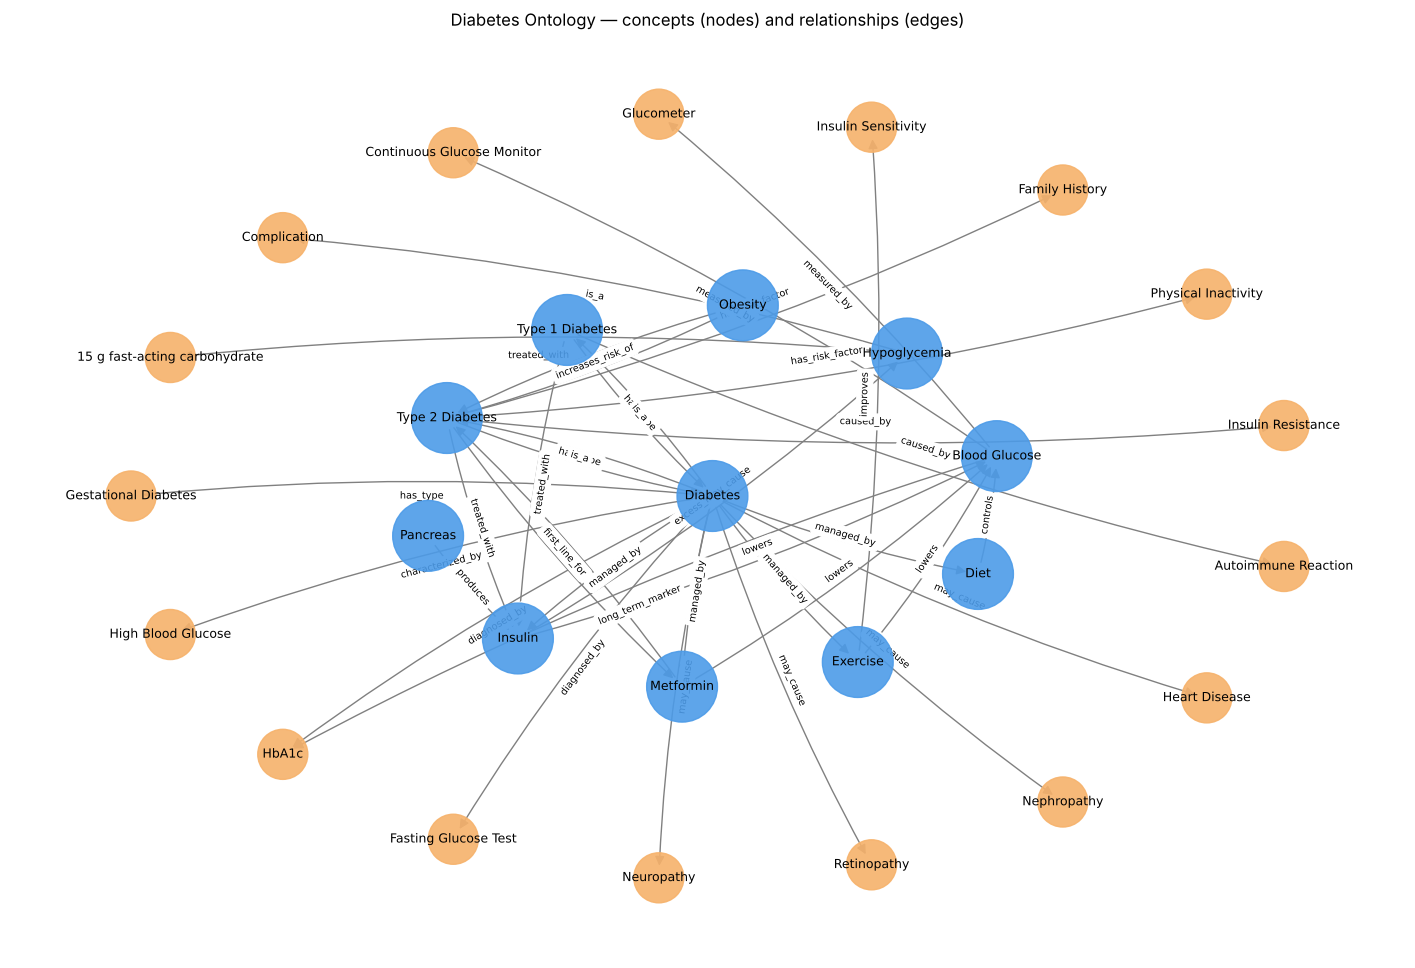

In [ ]:
# Visualise the ontology as a knowledge graph
G = nx.DiGraph()
for s, r, o in triples:
    G.add_edge(s, o, label=r)

plt.figure(figsize=(18, 12))
# Layout: 'Diabetes' in the centre, other main concepts in a ring, related values on the outer ring
inner = [c for c in ontology if c != "Diabetes"]
outer = list(dict.fromkeys(o for _, _, o in triples if o not in ontology))
pos = nx.shell_layout(G, nlist=[["Diabetes"], inner, outer])
core = set(ontology)
nx.draw_networkx_nodes(G, pos, node_size=[2600 if n in core else 1300 for n in G],
                       node_color=["#4C9BE8" if n in core else "#F6B26B" for n in G], alpha=0.9)
nx.draw_networkx_labels(G, pos, font_size=9)
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=14, edge_color="gray",
                       connectionstyle="arc3,rad=0.05")
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "label"), font_size=7)
plt.title("Diabetes Ontology — concepts (nodes) and relationships (edges)")
plt.axis("off")
plt.show()

## 4. NLP Processing — prepare text for machine learning  *(Requirement 4)*

Pipeline (as in Lab 10, extended with stopword removal):
**Lowercase → Tokenization → Stopword removal → Lemmatization**   e.g. `"books" → "book"`, `"feet" → "foot"`

In [ ]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words("english"))

def preprocess(text, verbose=False):
    # 1) Lowercase conversion
    text_lower = text.lower()
    # 2) Tokenization
    tokens = word_tokenize(text_lower)
    # keep only alphabetic tokens (drops punctuation and numbers)
    tokens = [t for t in tokens if t.isalpha()]
    # 3) Stopword removal
    no_stop = [t for t in tokens if t not in stop_words]
    # 4) Lemmatization (noun first, then verb:  "feet"->"foot", "eating"->"eat")
    lemmas = [lemmatizer.lemmatize(lemmatizer.lemmatize(t, pos="n"), pos="v") for t in no_stop]
    if verbose:
        print("Original     :", text)
        print("Lowercase    :", text_lower)
        print("Tokens       :", tokens)
        print("No stopwords :", no_stop)
        print("Lemmatized   :", lemmas)
        print()
    return " ".join(lemmas)

# Demonstrate each step on a few queries
for q in ["How should I take care of my feet with diabetes?",
          "Which foods should diabetics avoid?",
          "What are the side effects of Metformin?"]:
    preprocess(q, verbose=True)

df["clean_query"] = df["query"].apply(preprocess)
df[["query", "clean_query", "intent"]].head(10)

Original     : How should I take care of my feet with diabetes?
Lowercase    : how should i take care of my feet with diabetes?
Tokens       : ['how', 'should', 'i', 'take', 'care', 'of', 'my', 'feet', 'with', 'diabetes']
No stopwords : ['take', 'care', 'feet', 'diabetes']
Lemmatized   : ['take', 'care', 'foot', 'diabetes']

Original     : Which foods should diabetics avoid?
Lowercase    : which foods should diabetics avoid?
Tokens       : ['which', 'foods', 'should', 'diabetics', 'avoid']
No stopwords : ['foods', 'diabetics', 'avoid']
Lemmatized   : ['food', 'diabetic', 'avoid']

Original     : What are the side effects of Metformin?
Lowercase    : what are the side effects of metformin?
Tokens       : ['what', 'are', 'the', 'side', 'effects', 'of', 'metformin']
No stopwords : ['side', 'effects', 'metformin']
Lemmatized   : ['side', 'effect', 'metformin']



,query,clean_query,intent
0,What is diabetes?,diabetes,About_Diabetes
1,What are the different types of diabetes?,different type diabetes,About_Diabetes
2,What is the difference between type 1 and type...,difference type type diabetes,About_Diabetes
3,What is gestational diabetes?,gestational diabetes,About_Diabetes
4,What causes type 1 diabetes?,cause type diabetes,About_Diabetes
5,Why does type 2 diabetes happen?,type diabetes happen,About_Diabetes
6,What is prediabetes?,prediabetes,About_Diabetes
7,Is diabetes a lifelong disease?,diabetes lifelong disease,About_Diabetes
8,Can children get diabetes?,child get diabetes,About_Diabetes
9,How is diabetes diagnosed?,diabetes diagnose,About_Diabetes


## 5. Learning — TF-IDF feature extraction + classifier  *(Requirement 5)*

* **TF-IDF** turns each cleaned query into a numerical vector. Two TF-IDF views are combined:
  * **word-level TF-IDF** – one feature per lemma (e.g. `insulin`, `diet`);
  * **character n-gram TF-IDF** (3–5 characters inside words) – helps with spelling variants and unseen words,
    e.g. `jog`/`jogging`, `diabetic`/`diabetes`, `medicine`/`medication`. With only 120 training queries this raised cross-validated accuracy from ≈ 0.61 (word uni+bigrams) to ≈ 0.72.
* Three classifiers from the assignment are compared: **Naive Bayes, Logistic Regression and Linear SVM**.
* **Evaluation strategy:** the corpus is small (120 queries), so a single 75/25 split leaves only 3–4 test queries per intent and the score changes a lot depending on which queries land in the test set. Instead, **stratified 5-fold cross-validation** is used: the data is split into 5 parts, the model is trained on 4 and tested on the 5th, five times. **Every query is tested exactly once by a model that never saw it during training.**

In [ ]:
# TF-IDF demo (exactly like the lab slide)
demo_vectorizer = TfidfVectorizer()
X_demo = demo_vectorizer.fit_transform(df["clean_query"])
print("TF-IDF matrix shape (queries x vocabulary):", X_demo.shape)
print("Sample vocabulary:", list(demo_vectorizer.get_feature_names_out()[:25]))

# Top TF-IDF terms of one query
idx = df.index[df["query"].str.contains("feet")][0]
row = X_demo[idx].toarray()[0]
top = np.argsort(row)[::-1][:5]
print("\nTF-IDF weights for:", df.loc[idx, "query"], "->", {str(demo_vectorizer.get_feature_names_out()[i]): round(float(row[i]), 3) for i in top if row[i] > 0})

TF-IDF matrix shape (queries x vocabulary): (120, 200)
Sample vocabulary: ['act', 'active', 'activity', 'affect', 'always', 'amputation', 'avoid', 'become', 'best', 'better', 'blood', 'blur', 'body', 'breakfast', 'carbohydrate', 'care', 'cause', 'chance', 'change', 'check', 'child', 'complication', 'confirm', 'continuous', 'control']

TF-IDF weights for: How should I take care of my feet with diabetes? -> {'care': 0.62, 'take': 0.536, 'foot': 0.536, 'diabetes': 0.201}


In [ ]:
def make_pipeline(clf):
    features = FeatureUnion([
        ("word_tfidf", TfidfVectorizer(sublinear_tf=True)),
        ("char_tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True)),
    ])
    return Pipeline([("tfidf", features), ("clf", clf)])

X_all, y_all = df["clean_query"], df["intent"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Naive Bayes":         make_pipeline(MultinomialNB(alpha=0.1)),
    "Logistic Regression": make_pipeline(LogisticRegression(C=10, max_iter=2000)),
    "Linear SVM":          make_pipeline(LinearSVC(C=1.0)),
}

rows, cv_predictions = [], {}
for name, model in models.items():
    pred = cross_val_predict(model, X_all, y_all, cv=cv)     # out-of-fold prediction for every query
    cv_predictions[name] = pred
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_all, pred),
        "Precision (macro)": precision_score(y_all, pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_all, pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_all, pred, average="macro", zero_division=0),
    })

comparison = pd.DataFrame(rows).set_index("Model").round(3)
comparison

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,
Naive Bayes,0.717,0.748,0.717,0.717
Logistic Regression,0.717,0.765,0.717,0.724
Linear SVM,0.725,0.762,0.725,0.729


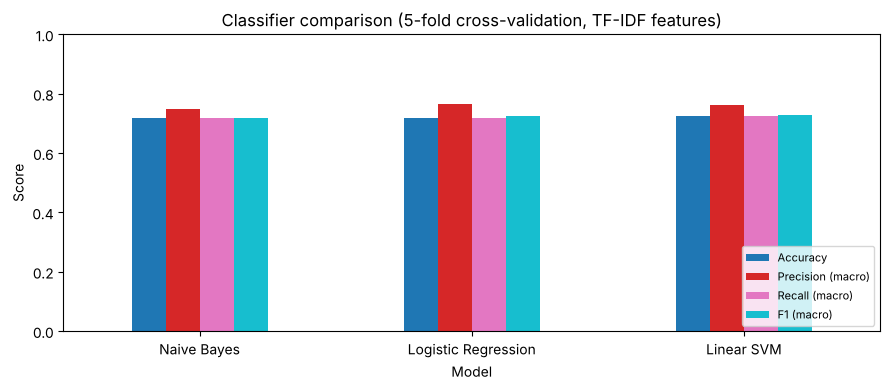

In [ ]:
comparison.plot(kind="bar", figsize=(9, 4), ylim=(0, 1), rot=0, colormap="tab10")
plt.title("Classifier comparison (5-fold cross-validation, TF-IDF features)")
plt.ylabel("Score")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

**Model choice:** Logistic Regression is used in the assistant. Its scores are in the same range as the others, and unlike `LinearSVC` it outputs **class probabilities** (`predict_proba`), which the reasoning layer needs for the *low-confidence* rule. Naive Bayes also gives probabilities but they are over-confident (often ≈ 100 %), which makes a confidence threshold useless.

## 5b. Evaluation — accuracy, precision, recall, F1 and confusion matrix  *(Requirement 6)*
Metrics for the chosen **TF-IDF + Logistic Regression** model, computed from the cross-validated predictions.

In [ ]:
y_pred = cv_predictions["Logistic Regression"]

print("Accuracy          :", round(accuracy_score(y_all, y_pred), 3))
print("Precision (macro) :", round(precision_score(y_all, y_pred, average="macro", zero_division=0), 3))
print("Recall (macro)    :", round(recall_score(y_all, y_pred, average="macro", zero_division=0), 3))
print("F1-score (macro)  :", round(f1_score(y_all, y_pred, average="macro", zero_division=0), 3))
print("\nClassification report (per intent):\n")
print(classification_report(y_all, y_pred, zero_division=0))

Accuracy          : 0.717
Precision (macro) : 0.765
Recall (macro)    : 0.717
F1-score (macro)  : 0.724

Classification report (per intent):

                precision    recall  f1-score   support

About_Diabetes       0.39      0.73      0.51        15
 Complications       0.67      0.40      0.50        15
          Diet       0.63      0.80      0.71        15
      Exercise       0.64      0.47      0.54        15
    Medication       1.00      0.87      0.93        15
    Monitoring       0.93      0.93      0.93        15
    Prevention       0.86      0.80      0.83        15
      Symptoms       1.00      0.73      0.85        15

      accuracy                           0.72       120
     macro avg       0.76      0.72      0.72       120
  weighted avg       0.76      0.72      0.72       120



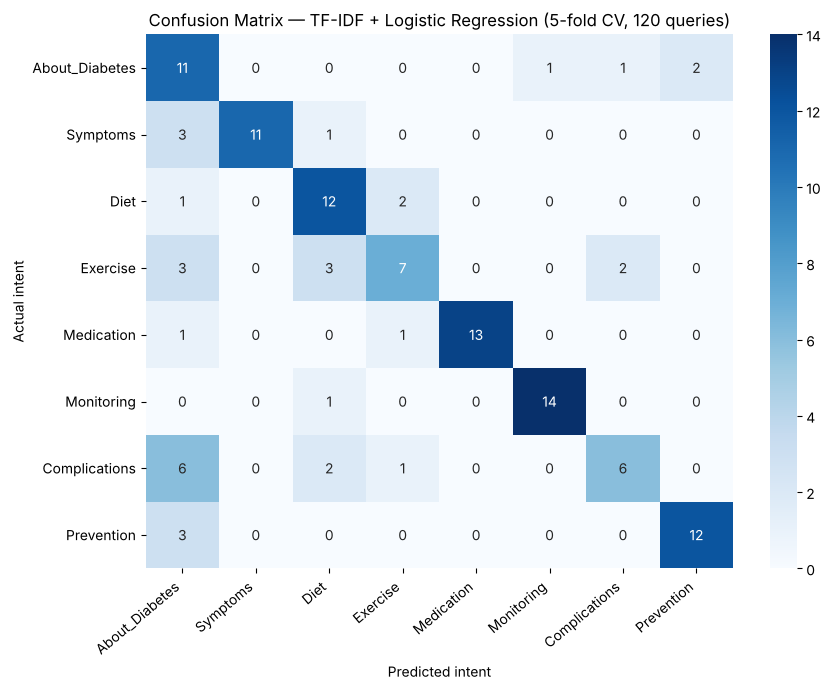

In [ ]:
intent_order = list(corpus.keys())
cm = confusion_matrix(y_all, y_pred, labels=intent_order)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=intent_order, yticklabels=intent_order)
plt.xlabel("Predicted intent")
plt.ylabel("Actual intent")
plt.title("Confusion Matrix — TF-IDF + Logistic Regression (5-fold CV, 120 queries)")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# Which queries were confused? (useful for error analysis)
mis = pd.DataFrame({"query": df["query"], "actual": y_all, "predicted": y_pred})
mis = mis[mis.actual != mis.predicted]
print(f"{len(mis)} of {len(df)} queries misclassified during cross-validation:")
mis

34 of 120 queries misclassified during cross-validation:


,query,actual,predicted
6,What is prediabetes?,About_Diabetes,Prevention
7,Is diabetes a lifelong disease?,About_Diabetes,Complications
8,Can children get diabetes?,About_Diabetes,Prevention
13,Which blood test confirms diabetes?,About_Diabetes,Monitoring
18,Can diabetes cause blurred vision?,Symptoms,About_Diabetes
20,What are the warning signs of type 2 diabetes?,Symptoms,About_Diabetes
21,Why do my wounds heal so slowly?,Symptoms,Diet
29,How do I know if I have diabetes?,Symptoms,About_Diabetes
33,Is fruit safe for diabetics?,Diet,Exercise
34,What is a good breakfast for diabetes?,Diet,About_Diabetes


**Observations**
* Intents with very distinctive words (*Monitoring*: glucometer, HbA1c, sugar level; *Medication*: insulin, metformin, dose) are recognised best (F1 ≈ 0.93).
* *Complications* and *Exercise* are the hardest: their queries are short and varied ("Is yoga helpful for diabetes?", "How does diabetes affect the eyes?"), so they are often pulled towards the general *About_Diabetes* intent. Some *Exercise* ↔ *Diet* confusion also appears because both are lifestyle topics ("walk daily", "control sugar").
* The word "diabetes" appears in almost every query, so short queries such as "Is yoga helpful for diabetes?" tend to drift towards *About_Diabetes*. More training queries per intent would reduce this.
* Low-probability predictions like these are caught by the **low-confidence rule (R5)** in the assistant, which asks the user to rephrase instead of giving a wrong answer.

### Final model
As the lab's workflow diagram explains, *the assistant does not train itself every time a user asks a question*. After evaluation, the chosen pipeline is **re-trained once on the full corpus**. The assistant then reuses this trained model for every new query.

In [ ]:
final_model = make_pipeline(LogisticRegression(C=10, max_iter=2000))
final_model.fit(df["clean_query"], df["intent"])
# Word vocabulary of the corpus — used by the 'unsupported query' rule
vocabulary = set(TfidfVectorizer().fit(df["clean_query"]).get_feature_names_out())
print("Final model trained on", len(df), "queries")
print("Word vocabulary size:", len(vocabulary), "| total TF-IDF features (word + char):",
      final_model.named_steps["tfidf"].transform(["x"]).shape[1])

Final model trained on 120 queries
Word vocabulary size: 200 | total TF-IDF features (word + char): 2364


## 6. Reasoning and Knowledge Retrieval  *(Requirements 7 & 8)*

### 6.1 Domain-specific knowledge base (one entry per intent)

In [ ]:
knowledge_base = {
    "About_Diabetes": {
        "answer": ("Diabetes is a long-term condition in which blood glucose (sugar) stays too high because the body "
                   "does not make enough insulin or cannot use insulin properly."),
        "points": [
            "Type 1: the immune system destroys insulin-producing cells in the pancreas; insulin is needed for life.",
            "Type 2 (most common): the body becomes resistant to insulin; linked to excess weight, inactivity and family history.",
            "Gestational diabetes: high blood sugar first found during pregnancy; usually goes away after delivery.",
            "Prediabetes: sugar is higher than normal but not yet in the diabetes range (HbA1c 5.7–6.4 %).",
            "Diagnosis: fasting glucose ≥ 126 mg/dL, HbA1c ≥ 6.5 %, or 2-hour OGTT ≥ 200 mg/dL.",
        ],
    },
    "Symptoms": {
        "answer": "Common symptoms of high blood sugar / diabetes include:",
        "points": [
            "Excessive thirst and frequent urination (especially at night).",
            "Constant hunger and unexplained weight loss.",
            "Tiredness, weakness and blurred vision.",
            "Slow-healing cuts or sores and frequent infections.",
            "Tingling or numbness in hands or feet.",
            "Type 2 diabetes may have no symptoms for years — get a blood test if you are at risk.",
        ],
    },
    "Diet": {
        "answer": "A diabetes-friendly diet focuses on controlling carbohydrates and choosing whole, fibre-rich foods.",
        "points": [
            "Use the plate method: ½ non-starchy vegetables, ¼ lean protein, ¼ whole grains/starch.",
            "Prefer low glycemic-index foods: whole grains, oats, legumes, vegetables, most whole fruits.",
            "Limit sugary drinks, sweets, white rice/bread, fried and processed foods.",
            "Rice and fruit can be eaten in controlled portions — pair them with protein or fibre.",
            "'Sugar-free' does not mean carbohydrate-free — always check the label.",
            "Eat at regular times and do not skip meals, especially if you take insulin.",
        ],
    },
    "Exercise": {
        "answer": "Physical activity lowers blood sugar and makes the body more sensitive to insulin.",
        "points": [
            "Aim for at least 150 minutes of moderate activity per week (e.g. 30 minutes brisk walking, 5 days a week).",
            "Add strength / resistance training 2–3 times per week.",
            "Yoga, cycling and swimming are all good options; avoid more than 2 days in a row without activity.",
            "A short walk after meals helps reduce post-meal sugar spikes.",
            "If you use insulin or sulfonylureas, check sugar before exercise and carry a fast-acting snack.",
        ],
    },
    "Medication": {
        "answer": "Diabetes medicines help keep blood sugar in the target range. Common options:",
        "points": [
            "Metformin: usual first-line tablet for type 2; reduces sugar output from the liver. Side effects: nausea, "
            "stomach upset, diarrhoea (take with food).",
            "Insulin: essential for type 1 and sometimes needed in type 2. Types: rapid-acting, short-acting, "
            "intermediate and long-acting (basal).",
            "Other classes: sulfonylureas, DPP-4 inhibitors, SGLT2 inhibitors and GLP-1 receptor agonists.",
            "Insulin storage: unopened in the fridge (2–8 °C), never frozen; the pen in use can stay at room temperature "
            "for the period stated on its label.",
            "Missed dose: follow the instructions given by your doctor/pharmacist — never double the next dose.",
        ],
    },
    "Monitoring": {
        "answer": "Regular monitoring shows how well diabetes is controlled. Typical targets for most adults with diabetes:",
        "points": [
            "Fasting / before meals: 80–130 mg/dL (normal without diabetes: 70–99 mg/dL).",
            "2 hours after meals: below 180 mg/dL.",
            "HbA1c (3-month average): below 7 % for most adults with diabetes.",
            "Below 70 mg/dL = hypoglycemia (low sugar) and needs treatment.",
            "Check as often as your doctor advises — several times a day if you use insulin.",
            "Glucometer: wash hands, prick the side of the fingertip, apply the drop to the strip, record the reading.",
            "A continuous glucose monitor (CGM) is a small sensor that measures glucose every few minutes.",
        ],
    },
    "Complications": {
        "answer": "Poorly controlled diabetes can damage blood vessels and nerves over time. Main complications:",
        "points": [
            "Hypoglycemia (sugar < 70 mg/dL): shakiness, sweating, confusion — treat with 15 g fast-acting sugar (rule of 15).",
            "Neuropathy: nerve damage causing tingling, pain or numbness, mostly in the feet.",
            "Retinopathy: damage to the retina that can lead to vision loss — get a yearly eye exam.",
            "Nephropathy: kidney damage — check urine albumin and kidney function yearly.",
            "Heart disease and stroke risk is 2–4 times higher.",
            "Foot care: inspect feet daily, keep them clean and dry, wear proper footwear, never walk barefoot.",
        ],
    },
    "Prevention": {
        "answer": "Type 2 diabetes can often be prevented or delayed with lifestyle changes (type 1 cannot be prevented).",
        "points": [
            "Losing 5–7 % of body weight reduces the risk of type 2 diabetes by more than half in people with prediabetes.",
            "Be active for at least 150 minutes per week.",
            "Eat more vegetables, whole grains and fibre; cut down on sugary drinks and refined carbs.",
            "Do not smoke, sleep well and manage stress.",
            "Get screened regularly (adults from age 35, or earlier if overweight with risk factors such as family history).",
            "Prediabetes can often be reversed to normal sugar levels with these changes.",
        ],
    },
}

assert set(knowledge_base) == set(corpus), "Knowledge base must cover every intent"
for intent, entry in knowledge_base.items():
    print(f"{intent:15s} -> {len(entry['points'])} knowledge points")

About_Diabetes  -> 5 knowledge points
Symptoms        -> 6 knowledge points
Diet            -> 6 knowledge points
Exercise        -> 5 knowledge points
Medication      -> 5 knowledge points
Monitoring      -> 7 knowledge points
Complications   -> 6 knowledge points
Prevention      -> 6 knowledge points


### 6.2 Reasoning rules  *(≥ 5 rules)*

| # | Rule | Condition (IF) | Action (THEN) |
|---|---|---|---|
| R1 | Greeting / farewell | query is a greeting, thanks or bye | reply politely, no classification |
| R2 | **Emergency escalation** | emergency keywords (unconscious, seizure, chest pain, …) or glucose < 54 / ≥ 400 mg/dL | stop, tell the user to call emergency services |
| R3 | **Unsupported query** | non-diabetes health topic, or no known domain words | say it is out of scope, suggest a doctor |
| R4 | Glucose-reading interpretation | query contains a sugar / HbA1c number | classify the value (low / normal / high) |
| R5 | **Low confidence** | top class probability < threshold | ask the user to rephrase, offer top-2 guesses |
| R6 | Medication safety | intent = Medication and query mentions stop / skip / double / change dose | add "do not change dose without your doctor" warning |
| R7 | Ontology enrichment | query mentions an ontology concept | append related facts from the ontology |

In [ ]:
CONFIDENCE_THRESHOLD = 0.40   # R5: minimum probability to trust the predicted intent

GREETINGS = {"hi", "hello", "hey", "good morning", "good evening", "namaste"}
THANKS    = {"thanks", "thank you", "thankyou", "thx"}
FAREWELLS = {"bye", "goodbye", "exit", "quit"}

EMERGENCY_KEYWORDS = [
    "unconscious", "passed out", "fainted", "faint", "collapse", "collapsed", "not responding", "unresponsive",
    "seizure", "seizures", "convulsion", "convulsions", "chest pain", "can't breathe", "cannot breathe", "difficulty breathing",
    "trouble breathing", "fruity breath", "severe vomiting", "keeps vomiting", "confused and sweating",
    "slurred speech", "emergency", "dying",
]

DIABETES_TERMS = [
    "diabet", "sugar", "glucose", "insulin", "metformin", "hba1c", "a1c", "glucometer", "pancrea",
    "hypoglyc", "hyperglyc", "carb", "glycemic", "neuropathy", "retinopathy", "nephropathy", "cgm",
]

OUT_OF_SCOPE_TERMS = [
    "cancer", "tumor", "covid", "corona", "fracture", "broken", "migraine", "asthma", "tooth", "dental",
    "malaria", "dengue", "tuberculosis", "hair loss", "acne", "skin rash", "pregnancy test",
    "depression", "anxiety", "fever", "cold", "cough", "flu", "allergy", "thyroid", "kidney stone",
    "hiv", "arthritis", "weather", "movie", "cricket", "football",
]

MED_CHANGE_WORDS = ["stop", "skip", "double", "increase", "decrease", "reduce", "change", "quit", "extra"]

DISCLAIMER = "ℹ️ This is general information, not medical advice. Please consult your doctor for personal guidance."


def contains_any(text, words):
    """Substring match (used for word stems such as 'diabet', 'hypoglyc')."""
    return any(w in text for w in words)


def contains_word(text, words):
    """Whole-word / whole-phrase match (so 'flu' does not match 'fluid')."""
    return any(re.search(r"\b" + re.escape(w) + r"\b", text) for w in words)


# ---- R1 ---------------------------------------------------------------------
def rule_greeting(q):
    clean = q.strip(" !.?").lower()
    if clean in GREETINGS:
        return "👋 Hello! I am your Diabetes Care Information Assistant. Ask me about diabetes types, symptoms, diet, exercise, medication, sugar monitoring, complications or prevention."
    if clean in THANKS:
        return "😊 You're welcome! Stay healthy."
    if clean in FAREWELLS:
        return "👋 Goodbye! Take care and keep your sugar in check."
    return None


# ---- R4 (helper used by R2 as well) -------------------------------------------
def extract_reading(q):
    """Return ('glucose', value) or ('hba1c', value) if the query contains a reading."""
    ql = q.lower()
    nums = [float(n) for n in re.findall(r"\d+(?:\.\d+)?", ql)]
    if not nums:
        return None
    if contains_any(ql, ["hba1c", "a1c"]):
        vals = [n for n in nums if n != 1 and 3 <= n <= 20]          # ignore the '1' in 'a1c'
        return ("hba1c", vals[0]) if vals else None
    if contains_any(ql, ["sugar", "glucose", "reading", "level", "mg"]):
        vals = [n for n in nums if 20 <= n <= 800]
        return ("glucose", vals[0]) if vals else None
    return None


def rule_reading(q):
    r = extract_reading(q)
    if r is None:
        return None
    kind, v = r
    if kind == "hba1c":
        if v < 5.7:
            return f"📊 An HbA1c of {v:g} % is in the normal range (< 5.7 %)."
        if v < 6.5:
            return f"📊 An HbA1c of {v:g} % is in the prediabetes range (5.7–6.4 %). Lifestyle changes can bring it back to normal."
        if v < 7:
            return f"📊 An HbA1c of {v:g} % is in the diabetes range but meets the usual target of < 7 % for people with diabetes."
        return f"📊 An HbA1c of {v:g} % is above the usual target of < 7 %. Please review your treatment plan with your doctor."
    # glucose (mg/dL)
    if v < 70:
        return (f"⚠️ {v:g} mg/dL is LOW (hypoglycemia). Follow the rule of 15: take 15 g of fast-acting sugar "
                "(½ cup juice, 3–4 glucose tablets or 1 tablespoon sugar), recheck after 15 minutes and repeat if still below 70.")
    if v <= 130:
        return f"✅ {v:g} mg/dL is within the usual fasting / before-meal target (80–130 mg/dL) for people with diabetes."
    if v < 180:
        return f"🟡 {v:g} mg/dL is above the fasting target but below 180 mg/dL, the usual 2-hour after-meal limit."
    if v < 250:
        return f"🟠 {v:g} mg/dL is HIGH (above 180 mg/dL). Drink water, follow your meal plan and medicines, and recheck later."
    return (f"🔴 {v:g} mg/dL is VERY HIGH. Check for ketones if you can, drink water and contact your doctor today. "
            "Seek emergency care if you have vomiting, confusion or difficulty breathing.")


# ---- R2 ---------------------------------------------------------------------
def rule_emergency(q):
    ql = q.lower()
    r = extract_reading(q)
    severe_reading = r is not None and r[0] == "glucose" and (r[1] < 54 or r[1] >= 400)
    if contains_word(ql, EMERGENCY_KEYWORDS) or severe_reading:
        msg = ("🚨 EMERGENCY: This may be a medical emergency. Call your local emergency number "
               "(India: 112 / 108) or go to the nearest hospital immediately.")
        if severe_reading and r[1] < 54:
            msg += "\nIf the person is conscious and can swallow, give 15–20 g of fast-acting sugar right now. Do NOT give food or drink to an unconscious person."
        elif severe_reading:
            msg += "\nA glucose level this high can mean diabetic ketoacidosis (DKA) or a hyperglycemic crisis."
        return msg
    return None


# ---- R3 ---------------------------------------------------------------------
def rule_unsupported(q, clean_q):
    ql = q.lower()
    in_domain = contains_any(ql, DIABETES_TERMS)
    known_words = [w for w in clean_q.split() if w in vocabulary]
    if (contains_word(ql, OUT_OF_SCOPE_TERMS) and not in_domain) or not known_words:
        return ("❓ Sorry, this question is outside my scope. I can only answer diabetes-related questions "
                "(types, symptoms, diet, exercise, medication, monitoring, complications and prevention). "
                "For other health concerns please consult a doctor.")
    return None


# ---- R5 ---------------------------------------------------------------------
def rule_low_confidence(probs, classes):
    top2 = np.argsort(probs)[::-1][:2]
    if probs[top2[0]] < CONFIDENCE_THRESHOLD:
        guesses = " or ".join(f"'{classes[i]}'" for i in top2)
        return (f"🤔 I'm not confident I understood (confidence {probs[top2[0]]:.0%}). "
                f"Did you mean a question about {guesses}? Please rephrase with more detail.")
    return None


# ---- R6 ---------------------------------------------------------------------
def rule_medication_safety(q, intent):
    if intent == "Medication" and contains_word(q.lower(), MED_CHANGE_WORDS):
        return "💊 Safety note: never stop, skip, double or change a diabetes medicine dose without talking to your doctor."
    return None


# ---- R7 ---------------------------------------------------------------------
# Everyday words that refer to ontology concepts
CONCEPT_ALIASES = {
    "blood sugar": "Blood Glucose", "glucose": "Blood Glucose", "sugar level": "Blood Glucose",
    "type 1": "Type 1 Diabetes", "type 2": "Type 2 Diabetes", "low sugar": "Hypoglycemia",
    "workout": "Exercise", "walking": "Exercise", "food": "Diet", "overweight": "Obesity",
}

def rule_ontology(q, intent, max_facts=3):
    ql = q.lower()
    found = [c for c in ontology if c.lower() in ql]
    found += [c for alias, c in CONCEPT_ALIASES.items() if alias in ql and c not in found]
    # the generic concept 'Diabetes' appears in almost every query: use it only for general questions
    if "Diabetes" in found and (intent != "About_Diabetes" or len(found) > 1):
        found.remove("Diabetes")
    facts = []
    for concept in found:
        for rel, objs in ontology[concept].items():
            objs = objs if isinstance(objs, list) else [objs]
            facts.append(f"{concept} {rel.replace('_', ' ')} {', '.join(objs)}")
    return facts[:max_facts]


# Quick unit checks of the rules
print(rule_greeting("Hello!"))
print(rule_emergency("My father fainted and his sugar is 40"))
print(rule_reading("my sugar level is 65"))
print(rule_reading("My HbA1c is 8.2"))
print(rule_ontology("how does metformin work", "Medication"))

👋 Hello! I am your Diabetes Care Information Assistant. Ask me about diabetes types, symptoms, diet, exercise, medication, sugar monitoring, complications or prevention.
🚨 EMERGENCY: This may be a medical emergency. Call your local emergency number (India: 112 / 108) or go to the nearest hospital immediately.
If the person is conscious and can swallow, give 15–20 g of fast-acting sugar right now. Do NOT give food or drink to an unconscious person.
⚠️ 65 mg/dL is LOW (hypoglycemia). Follow the rule of 15: take 15 g of fast-acting sugar (½ cup juice, 3–4 glucose tablets or 1 tablespoon sugar), recheck after 15 minutes and repeat if still below 70.
📊 An HbA1c of 8.2 % is above the usual target of < 7 %. Please review your treatment plan with your doctor.
['Metformin lowers Blood Glucose', 'Metformin first line for Type 2 Diabetes']


### 6.3 Knowledge retrieval (lab example: `print(knowledge[intent])`)

In [ ]:
def retrieve_knowledge(intent):
    entry = knowledge_base[intent]
    return entry["answer"] + "\n" + "\n".join(f"  • {p}" for p in entry["points"])

print(retrieve_knowledge("Exercise"))

Physical activity lowers blood sugar and makes the body more sensitive to insulin.
  • Aim for at least 150 minutes of moderate activity per week (e.g. 30 minutes brisk walking, 5 days a week).
  • Add strength / resistance training 2–3 times per week.
  • Yoga, cycling and swimming are all good options; avoid more than 2 days in a row without activity.
  • A short walk after meals helps reduce post-meal sugar spikes.
  • If you use insulin or sulfonylureas, check sugar before exercise and carry a fast-acting snack.


## 7. Cognitive Assistant — integrate all components  *(Requirement 9)*

`assistant(query)` = **Process query → Predict category → Apply rules → Retrieve response → return response** (the skeleton from the lab slide).

In [ ]:
def assistant(query, show_details=True):
    query = query.strip()
    if not query:
        return "Please type a question about diabetes."

    # R1 — greeting / farewell
    reply = rule_greeting(query)
    if reply:
        return reply

    # R2 — emergency escalation has the highest priority
    reply = rule_emergency(query)
    if reply:
        return reply

    # 1. Process query (NLP)
    clean_q = preprocess(query)

    # R3 — unsupported query
    reply = rule_unsupported(query, clean_q)
    if reply:
        return reply

    # R4 — a specific sugar / HbA1c reading is answered directly
    reading_reply = rule_reading(query)

    # 2. Predict category (ML)
    probs = final_model.predict_proba([clean_q])[0]
    classes = final_model.classes_
    best = int(np.argmax(probs))
    intent, confidence = classes[best], probs[best]

    # R5 — low confidence (skipped if R4 already understood the reading)
    if reading_reply is None:
        reply = rule_low_confidence(probs, classes)
        if reply:
            return reply

    # 3. Retrieve response (knowledge base)
    parts = []
    if show_details:
        parts.append(f"[Intent: {intent} | Category: {intent_to_category[intent]} | Confidence: {confidence:.0%}]")
    if reading_reply:
        parts.append(reading_reply)
    parts.append(retrieve_knowledge(intent))

    # R6 — medication safety
    safety = rule_medication_safety(query, intent)
    if safety:
        parts.append(safety)

    # R7 — ontology enrichment
    facts = rule_ontology(query, intent)
    if facts:
        parts.append("🔗 Related facts (ontology): " + "; ".join(facts) + ".")

    parts.append(DISCLAIMER)
    return "\n".join(parts)


print(assistant("How should I store my insulin?"))

[Intent: Medication | Category: Treatment & Monitoring | Confidence: 94%]
Diabetes medicines help keep blood sugar in the target range. Common options:
  • Metformin: usual first-line tablet for type 2; reduces sugar output from the liver. Side effects: nausea, stomach upset, diarrhoea (take with food).
  • Insulin: essential for type 1 and sometimes needed in type 2. Types: rapid-acting, short-acting, intermediate and long-acting (basal).
  • Other classes: sulfonylureas, DPP-4 inhibitors, SGLT2 inhibitors and GLP-1 receptor agonists.
  • Insulin storage: unopened in the fridge (2–8 °C), never frozen; the pen in use can stay at room temperature for the period stated on its label.
  • Missed dose: follow the instructions given by your doctor/pharmacist — never double the next dose.
🔗 Related facts (ontology): Insulin lowers Blood Glucose; Insulin excess may cause Hypoglycemia.
ℹ️ This is general information, not medical advice. Please consult your doctor for personal guidance.


## Testing the assistant

The assignment asks for tests with:
1. a query belonging to **each** defined intent,
2. a **differently worded** query,
3. an **unsupported** healthcare query,
4. a **low-confidence** query,
5. an **emergency-related** query.

In [ ]:
def show(title, q):
    print("=" * 100)
    print(f"{title}\nUSER : {q}\nBOT  : " + assistant(q).replace("\n", "\n       "))

# Test 1 — one NEW query (not in the training corpus) for each intent
test_per_intent = {
    "About_Diabetes": "Explain what type 1 diabetes is",
    "Symptoms":       "What symptoms show that someone has diabetes?",
    "Diet":           "Which foods are best to eat for a diabetic?",
    "Exercise":       "Is walking a good exercise for diabetes?",
    "Medication":     "What medicine do doctors give for type 2 diabetes?",
    "Monitoring":     "How often should I test my sugar level?",
    "Complications":  "Can diabetes cause damage to my eyes and kidneys?",
    "Prevention":     "What can I do to avoid getting type 2 diabetes?",
}
results = []
for expected, q in test_per_intent.items():
    probs = final_model.predict_proba([preprocess(q)])[0]
    pred = final_model.classes_[np.argmax(probs)]
    results.append({"Query": q, "Expected": expected, "Predicted": pred,
                    "Confidence": f"{probs.max():.0%}", "Correct": "✅" if pred == expected else "❌"})
pd.DataFrame(results)

,Query,Expected,Predicted,Confidence,Correct
0,Explain what type 1 diabetes is,About_Diabetes,About_Diabetes,88%,✅
1,What symptoms show that someone has diabetes?,Symptoms,Symptoms,86%,✅
2,Which foods are best to eat for a diabetic?,Diet,Diet,98%,✅
3,Is walking a good exercise for diabetes?,Exercise,Exercise,95%,✅
4,What medicine do doctors give for type 2 diabe...,Medication,Medication,66%,✅
5,How often should I test my sugar level?,Monitoring,Monitoring,98%,✅
6,Can diabetes cause damage to my eyes and kidneys?,Complications,Complications,92%,✅
7,What can I do to avoid getting type 2 diabetes?,Prevention,Prevention,58%,✅


In [ ]:
# Full responses for each intent
for expected, q in test_per_intent.items():
    show(f"TEST 1 — Intent: {expected}", q)

TEST 1 — Intent: About_Diabetes
USER : Explain what type 1 diabetes is
BOT  : [Intent: About_Diabetes | Category: Understanding Diabetes | Confidence: 88%]
       Diabetes is a long-term condition in which blood glucose (sugar) stays too high because the body does not make enough insulin or cannot use insulin properly.
         • Type 1: the immune system destroys insulin-producing cells in the pancreas; insulin is needed for life.
         • Type 2 (most common): the body becomes resistant to insulin; linked to excess weight, inactivity and family history.
         • Gestational diabetes: high blood sugar first found during pregnancy; usually goes away after delivery.
         • Prediabetes: sugar is higher than normal but not yet in the diabetes range (HbA1c 5.7–6.4 %).
         • Diagnosis: fasting glucose ≥ 126 mg/dL, HbA1c ≥ 6.5 %, or 2-hour OGTT ≥ 200 mg/dL.
       🔗 Related facts (ontology): Type 1 Diabetes is a Diabetes; Type 1 Diabetes caused by Autoimmune Reaction; Type 1 Dia

In [ ]:
show("TEST 2 — Differently worded query (Diet — no 'eat'/'food'/'diet' words)",
     "Which meals are healthy if my sugar is high?")
show("TEST 2 — Differently worded query (Exercise — no 'exercise'/'workout' words)",
     "Will going for a jog every morning help with my blood glucose?")

TEST 2 — Differently worded query (Diet — no 'eat'/'food'/'diet' words)
USER : Which meals are healthy if my sugar is high?
BOT  : [Intent: Diet | Category: Lifestyle Management | Confidence: 51%]
       A diabetes-friendly diet focuses on controlling carbohydrates and choosing whole, fibre-rich foods.
         • Use the plate method: ½ non-starchy vegetables, ¼ lean protein, ¼ whole grains/starch.
         • Prefer low glycemic-index foods: whole grains, oats, legumes, vegetables, most whole fruits.
         • Limit sugary drinks, sweets, white rice/bread, fried and processed foods.
         • Rice and fruit can be eaten in controlled portions — pair them with protein or fibre.
         • 'Sugar-free' does not mean carbohydrate-free — always check the label.
         • Eat at regular times and do not skip meals, especially if you take insulin.
       ℹ️ This is general information, not medical advice. Please consult your doctor for personal guidance.
TEST 2 — Differently worded query 

In [ ]:
show("TEST 3 — Unsupported healthcare query", "How do I treat a migraine headache?")
show("TEST 3 — Unsupported healthcare query", "What are the symptoms of dengue fever?")

TEST 3 — Unsupported healthcare query
USER : How do I treat a migraine headache?
BOT  : ❓ Sorry, this question is outside my scope. I can only answer diabetes-related questions (types, symptoms, diet, exercise, medication, monitoring, complications and prevention). For other health concerns please consult a doctor.
TEST 3 — Unsupported healthcare query
USER : What are the symptoms of dengue fever?
BOT  : ❓ Sorry, this question is outside my scope. I can only answer diabetes-related questions (types, symptoms, diet, exercise, medication, monitoring, complications and prevention). For other health concerns please consult a doctor.


In [ ]:
show("TEST 4 — Low-confidence query", "Is this normal in diabetes?")
show("TEST 4 — Low-confidence query", "diabetes and sugar")

TEST 4 — Low-confidence query
USER : Is this normal in diabetes?
BOT  : 🤔 I'm not confident I understood (confidence 27%). Did you mean a question about 'About_Diabetes' or 'Monitoring'? Please rephrase with more detail.
TEST 4 — Low-confidence query
USER : diabetes and sugar
BOT  : 🤔 I'm not confident I understood (confidence 32%). Did you mean a question about 'About_Diabetes' or 'Complications'? Please rephrase with more detail.


In [ ]:
show("TEST 5 — Emergency query", "My father is diabetic and he just fainted and is not responding")
show("TEST 5 — Emergency query (severe low sugar reading)", "My sugar level is 45 and I am shaking")
show("TEST 5 — Emergency query (very high reading)", "Glucose reading shows 450 mg/dL")

TEST 5 — Emergency query
USER : My father is diabetic and he just fainted and is not responding
BOT  : 🚨 EMERGENCY: This may be a medical emergency. Call your local emergency number (India: 112 / 108) or go to the nearest hospital immediately.
TEST 5 — Emergency query (severe low sugar reading)
USER : My sugar level is 45 and I am shaking
BOT  : 🚨 EMERGENCY: This may be a medical emergency. Call your local emergency number (India: 112 / 108) or go to the nearest hospital immediately.
       If the person is conscious and can swallow, give 15–20 g of fast-acting sugar right now. Do NOT give food or drink to an unconscious person.
TEST 5 — Emergency query (very high reading)
USER : Glucose reading shows 450 mg/dL
BOT  : 🚨 EMERGENCY: This may be a medical emergency. Call your local emergency number (India: 112 / 108) or go to the nearest hospital immediately.
       A glucose level this high can mean diabetic ketoacidosis (DKA) or a hyperglycemic crisis.


In [ ]:
show("EXTRA — Glucose reading rule (R4)", "My fasting sugar level is 150, is that bad?")
show("EXTRA — Medication safety rule (R6)", "Can I stop taking metformin?")
show("EXTRA — Greeting rule (R1)", "hello")

EXTRA — Glucose reading rule (R4)
USER : My fasting sugar level is 150, is that bad?
BOT  : [Intent: Monitoring | Category: Treatment & Monitoring | Confidence: 92%]
       🟡 150 mg/dL is above the fasting target but below 180 mg/dL, the usual 2-hour after-meal limit.
       Regular monitoring shows how well diabetes is controlled. Typical targets for most adults with diabetes:
         • Fasting / before meals: 80–130 mg/dL (normal without diabetes: 70–99 mg/dL).
         • 2 hours after meals: below 180 mg/dL.
         • HbA1c (3-month average): below 7 % for most adults with diabetes.
         • Below 70 mg/dL = hypoglycemia (low sugar) and needs treatment.
         • Check as often as your doctor advises — several times a day if you use insulin.
         • Glucometer: wash hands, prick the side of the fingertip, apply the drop to the strip, record the reading.
         • A continuous glucose monitor (CGM) is a small sensor that measures glucose every few minutes.
       🔗 Related f

In [ ]:
# Summary table of the five required test scenarios
scenarios = [
    ("Each intent (example: Medication)", "What medicine do doctors give for type 2 diabetes?"),
    ("Differently worded", "Which meals are healthy if my sugar is high?"),
    ("Unsupported healthcare", "How do I treat a migraine headache?"),
    ("Low confidence", "Is this normal in diabetes?"),
    ("Emergency", "My father is diabetic and he just fainted and is not responding"),
]
pd.DataFrame([{"Scenario": s, "Query": q, "Response (first line)": assistant(q).split("\n")[0][:110]}
              for s, q in scenarios])

,Scenario,Query,Response (first line)
0,Each intent (example: Medication),What medicine do doctors give for type 2 diabe...,[Intent: Medication | Category: Treatment & Mo...
1,Differently worded,Which meals are healthy if my sugar is high?,[Intent: Diet | Category: Lifestyle Management...
2,Unsupported healthcare,How do I treat a migraine headache?,"❓ Sorry, this question is outside my scope. I ..."
3,Low confidence,Is this normal in diabetes?,🤔 I'm not confident I understood (confidence 2...
4,Emergency,My father is diabetic and he just fainted and ...,🚨 EMERGENCY: This may be a medical emergency. ...


## 8. Deployment — interactive interface in Google Colab  *(Requirement 10)*

**Option A – chat widget (recommended in Colab):** type a question and press **Enter** or click **Ask**. You can ask as many questions as you like; the whole conversation stays on screen.

In [ ]:
import html
import ipywidgets as widgets
from IPython.display import display, HTML

chat_history = []

title = widgets.HTML("<h3>🩺 Diabetes Care Information Assistant</h3>"
                     "<p style='color:gray'>Ask about diabetes types, symptoms, diet, exercise, medication, "
                     "sugar monitoring, complications or prevention.</p>")
text_box = widgets.Text(placeholder="Type your question and press Enter…", layout=widgets.Layout(width="70%"))
ask_btn = widgets.Button(description="Ask", button_style="primary", icon="paper-plane")
clear_btn = widgets.Button(description="Clear chat", icon="trash")
chat_out = widgets.Output(layout=widgets.Layout(border="1px solid #ccc", padding="8px",
                                                max_height="500px", overflow="auto"))

def render():
    chat_out.clear_output()
    with chat_out:
        if not chat_history:
            display(HTML("<i>No messages yet.</i>"))
        for who, msg in chat_history:
            bg, name = ("#DCF2FF", "🧑 You") if who == "user" else ("#F1F1F1", "🤖 Assistant")
            display(HTML(f"<div style='background:{bg};color:#111;padding:8px 12px;margin:6px 0;border-radius:10px;"
                         f"white-space:pre-wrap;font-family:sans-serif'><b>{name}:</b><br>{html.escape(msg)}</div>"))

def on_ask(_=None):
    q = text_box.value.strip()
    if not q:
        return
    chat_history.append(("user", q))
    chat_history.append(("bot", assistant(q)))
    text_box.value = ""
    render()

def on_clear(_):
    chat_history.clear()
    render()

ask_btn.on_click(on_ask)
clear_btn.on_click(on_clear)
text_box.on_submit(on_ask)      # Enter key

render()
display(widgets.VBox([title, widgets.HBox([text_box, ask_btn, clear_btn]), chat_out]))

**Option B – text loop (same as the Lab 10 `while True` loop):** run the cell below and type questions; type `exit` to stop.

In [ ]:
def chat_loop():
    print("Ask the Diabetes Care Assistant anything (type 'exit' to end):\n")
    while True:
        user_input = input("You: ")
        if user_input.lower().strip() in ("exit", "quit", "bye"):
            print("Assistant: Bye! Stay healthy and keep your sugar in check.")
            break
        print("Assistant:", assistant(user_input).replace("\n", "\n           "), "\n")

chat_loop()